In [ ]:
!pip -q install datasets scikit-learn seaborn matplotlib nltk

import re
import random
import numpy as np
import pandas as pd
import torch
import nltk
from collections import Counter
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Download Twitter sentiment dataset safely
try:
    # Use cardiffnlp/tweet_eval directly to bypass standard dataset repository hub errors
    dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    train_df = pd.DataFrame(dataset["train"])
    val_df = pd.DataFrame(dataset["validation"])
    test_df = pd.DataFrame(dataset["test"])
except Exception as e:
    print("Hugging Face dataset load failed, falling back to NLTK Twitter dataset:", e)
    nltk.download('twitter_samples')
    from nltk.corpus import twitter_samples
    # Fallback structure matching the labels
    pos_tweets = twitter_samples.strings('positive_tweets.json')
    neg_tweets = twitter_samples.strings('negative_tweets.json')

    # Map 0 = Negative, 1 = Neutral, 2 = Positive (NLTK has positive and negative)
    all_tweets = pos_tweets + neg_tweets
    all_labels = [2] * len(pos_tweets) + [0] * len(neg_tweets)

    full_df = pd.DataFrame({"text": all_tweets, "label": all_labels})
    full_df = full_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

    train_df = full_df.iloc[:int(0.8*len(full_df))].copy()
    val_df = full_df.iloc[int(0.8*len(full_df)):int(0.9*len(full_df))].copy()
    test_df = full_df.iloc[int(0.9*len(full_df)):].copy()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"[^a-z0-9!?'\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for df in [train_df, val_df, test_df]:
    df["text"] = df["text"].apply(clean_text)

# Build vocabulary using training data only
MAX_VOCAB = 20000
MAX_LEN = 50
PAD, UNK = 0, 1

counter = Counter(
    word
    for text in train_df["text"]
    for word in text.split()
)

vocab = {"<PAD>": PAD, "<UNK>": UNK}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_text(text):
    tokens = [vocab.get(w, UNK) for w in text.split()[:MAX_LEN]]
    tokens = tokens + [PAD] * (MAX_LEN - len(tokens))
    return tokens

X_train = torch.tensor(
    np.array([encode_text(t) for t in train_df["text"]]),
    dtype=torch.long
)
X_val = torch.tensor(
    np.array([encode_text(t) for t in val_df["text"]]),
    dtype=torch.long
)
X_test = torch.tensor(
    np.array([encode_text(t) for t in test_df["text"]]),
    dtype=torch.long
)

y_train = torch.tensor(train_df["label"].to_numpy(), dtype=torch.long)
y_val = torch.tensor(val_df["label"].to_numpy(), dtype=torch.long)
y_test = torch.tensor(test_df["label"].to_numpy(), dtype=torch.long)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("Vocabulary size:", len(vocab))
print("Classes: 0 = Negative, 1 = Neutral, 2 = Positive")

Device: cpu
Training samples: 45615
Validation samples: 2000
Testing samples: 12284
Vocabulary size: 20000
Classes: 0 = Negative, 1 = Neutral, 2 = Positive


In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Explicitly set PAD index
PAD_IDX = 0

class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128,
                 hidden_dim=128, num_classes=3):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, embedding_dim, padding_idx=PAD_IDX
        )
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        output = self.dropout(hidden[-1])
        return self.fc(output)

model = SentimentLSTM(len(vocab)).to(device)

print(model)
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

SentimentLSTM(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)
Total parameters: 2692483


In [ ]:

BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 0.001

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=BATCH_SIZE
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE
)

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

    train_loss = total_loss / len(X_train)

    model.eval()
    val_loss_sum = 0
    val_preds, val_labels = [], []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            outputs = model(xb)
            loss = criterion(outputs, yb)

            val_loss_sum += loss.item() * xb.size(0)
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_labels.extend(yb.cpu().numpy())

    val_loss = val_loss_sum / len(X_val)
    val_acc = accuracy_score(val_labels, val_preds)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_acc:.4f}"
    )

print("Training completed.")


Epoch 1/5 | Train Loss: 1.0186 | Val Loss: 1.0184 | Val Accuracy: 0.4345
Epoch 2/5 | Train Loss: 1.0169 | Val Loss: 1.0183 | Val Accuracy: 0.4345
Epoch 3/5 | Train Loss: 1.0162 | Val Loss: 1.0182 | Val Accuracy: 0.4345
Epoch 4/5 | Train Loss: 1.0162 | Val Loss: 1.0203 | Val Accuracy: 0.4345
Epoch 5/5 | Train Loss: 1.0162 | Val Loss: 1.0186 | Val Accuracy: 0.4345
Training completed.


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix

test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

model.eval()
test_preds, test_labels = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        outputs = model(xb)

        test_preds.extend(outputs.argmax(1).cpu().numpy())
        test_labels.extend(yb.numpy())

test_accuracy = accuracy_score(test_labels, test_preds)
test_f1 = f1_score(
    test_labels, test_preds,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Macro F1 Score: {test_f1:.4f}")
print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))


Test Accuracy: 0.4833
Macro F1 Score: 0.2172

Classification Report:
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00      3972
     Neutral       0.48      1.00      0.65      5937
    Positive       0.00      0.00      0.00      2375

    accuracy                           0.48     12284
   macro avg       0.16      0.33      0.22     12284
weighted avg       0.23      0.48      0.31     12284



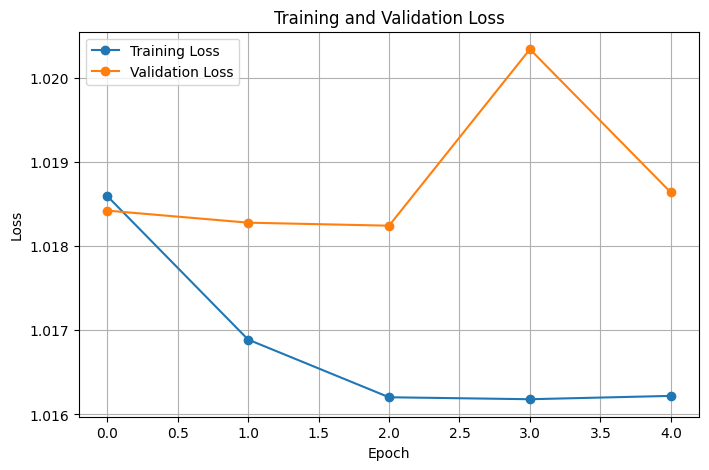

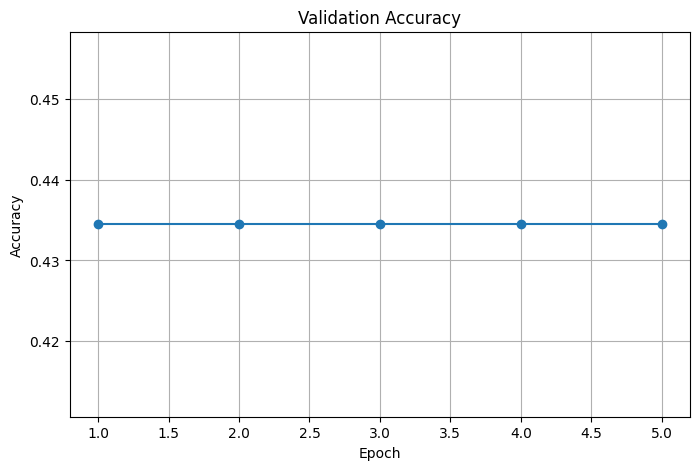

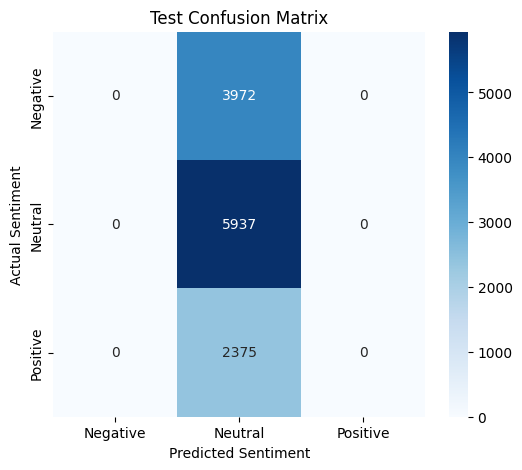

Tweet: what do these '1 2 naked pics' have to do with anything? they're not even like that
Actual: Neutral | Predicted: Neutral
------------------------------------------------------------
Tweet: oh i had a blue penis while i was this playing with google earth vr
Actual: Neutral | Predicted: Neutral
------------------------------------------------------------
Tweet: that's coming but i think the victims are going to be medicaid recipients
Actual: Neutral | Predicted: Neutral
------------------------------------------------------------
Tweet: i think i may be finally in with the in crowd mannequinchallenge grads2014
Actual: Positive | Predicted: Neutral
------------------------------------------------------------
Tweet: wow first hugo chavez and now fidel castro danny glover michael moore oliver stone and sean penn are running out of heroes
Actual: Negative | Predicted: Neutral
------------------------------------------------------------
Tweet: savchenko now saakashvili took drug test l

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, EPOCHS + 1),
    history["val_accuracy"],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy")
plt.grid(True)
plt.show()

# Confusion matrix
cm = confusion_matrix(
    test_labels, test_preds, labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Test Confusion Matrix")
plt.show()

# Display example predictions
sentiment_names = ["Negative", "Neutral", "Positive"]

for i in range(10):
    text = test_df.iloc[i]["text"]
    actual = sentiment_names[test_labels[i]]
    predicted = sentiment_names[test_preds[i]]

    print("Tweet:", text)
    print("Actual:", actual, "| Predicted:", predicted)
    print("-" * 60)

# Test your own tweet
def predict_sentiment(text):
    model.eval()
    cleaned = clean_text(text)
    encoded = torch.tensor(
        [encode_text(cleaned)], dtype=torch.long
    ).to(device)

    with torch.no_grad():
        probabilities = torch.softmax(model(encoded), dim=1)[0]
        prediction = probabilities.argmax().item()

    return sentiment_names[prediction], probabilities.cpu().numpy()

print("\nCustom Prediction:")
print(predict_sentiment("I really love this product!")[0])


Training baseline model...

Model Comparison:
                       Model  Accuracy  Macro F1
TF-IDF + Logistic Regression    0.5898    0.5714
                PyTorch LSTM    0.4833    0.2172


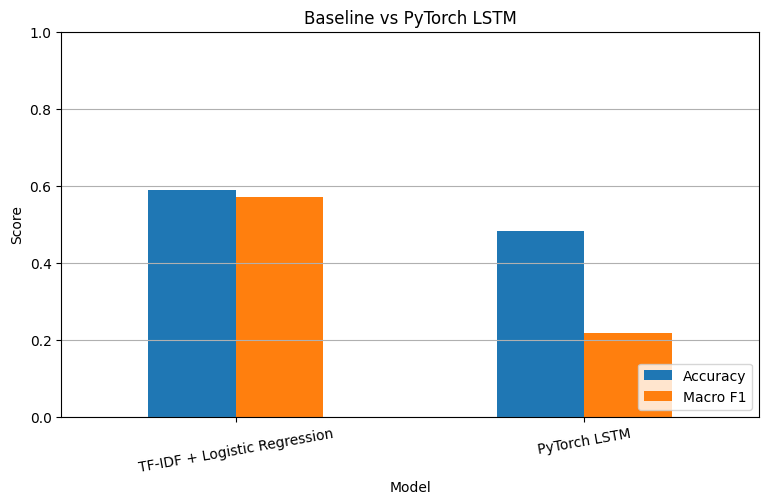


OBSERVATIONS
Baseline accuracy: 0.5898
LSTM accuracy: 0.4833
Baseline macro F1: 0.5714
LSTM macro F1: 0.2172
The baseline achieved a higher macro F1 score.
Check training and validation loss for possible overfitting.
Review the loss curves and confusion matrix to identify
learning trends and sentiment classes that are harder to predict.


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Build and train baseline model
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=300,
        C=2.0,
        random_state=SEED
    ))
])

print("Training baseline model...")
baseline.fit(train_df["text"], train_df["label"])

baseline_preds = baseline.predict(test_df["text"])

# Calculate metrics
baseline_accuracy = accuracy_score(
    test_df["label"], baseline_preds
)
baseline_f1 = f1_score(
    test_df["label"], baseline_preds,
    average="macro"
)

results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression", "PyTorch LSTM"],
    "Accuracy": [baseline_accuracy, test_accuracy],
    "Macro F1": [baseline_f1, test_f1]
})

print("\nModel Comparison:")
print(results.round(4).to_string(index=False))

# Visual comparison
results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("Baseline vs PyTorch LSTM")
plt.ylabel("Score")
plt.xticks(rotation=10)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

# Automatically summarize the observed results
print("\nOBSERVATIONS")
print(f"Baseline accuracy: {baseline_accuracy:.4f}")
print(f"LSTM accuracy: {test_accuracy:.4f}")
print(f"Baseline macro F1: {baseline_f1:.4f}")
print(f"LSTM macro F1: {test_f1:.4f}")

if test_f1 > baseline_f1:
    print("The LSTM achieved a higher macro F1 score.")
elif test_f1 < baseline_f1:
    print("The baseline achieved a higher macro F1 score.")
else:
    print("Both models achieved the same macro F1 score.")

if history["val_loss"][-1] < history["train_loss"][-1]:
    print("Final validation loss is below training loss.")
else:
    print("Check training and validation loss for possible overfitting.")

print("Review the loss curves and confusion matrix to identify")
print("learning trends and sentiment classes that are harder to predict.")
